# Intara — LLM telemetry analysis (`llm_calls`)

What this notebook answers, from one table of per-call gateway telemetry:

1. **Who actually served the calls** (free-tier provider mix)
2. **Failure causes** — why the provider chain fell through (quota vs provider-side validation)
3. **Latency by provider** — the real reason Groq became the workhorse
4. **Truncation** — which provider cuts output off, and how often
5. **Parse-outcome attribution** — the gap this analysis found in the schema, and the fix (session 33)

**Data:** `evals/telemetry/llm_calls.csv`, exported from Supabase (429 calls, 2026-10-12 → 2026-10-16).
Prompts are never stored in this table — routing, usage, timing and outcomes only.

**Regenerate:** run some live builds, then `python scripts/export_llm_calls.py`.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_rows", 30)
plt.rcParams.update({"figure.figsize": (9, 3.6), "axes.grid": True,
                     "grid.alpha": 0.25, "axes.spines.top": False,
                     "axes.spines.right": False})

def repo_root() -> Path:
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "evals" / "telemetry" / "llm_calls.csv").exists():
            return p
    raise FileNotFoundError("run `python scripts/export_llm_calls.py` from the repo root first")

CSV = repo_root() / "evals" / "telemetry" / "llm_calls.csv"
df = pd.read_csv(CSV, parse_dates=["created_at"])
print(f"{len(df)} calls | {df.created_at.min().date()} → {df.created_at.max().date()} | "
      f"{df.provider.nunique()} providers, {df.model.nunique()} models")
df.head(3)

429 calls | 2026-10-12 → 2026-10-16 | 4 providers, 5 models


,created_at,provider,model,agent,step_key,prompt_version,tokens_in,tokens_out,latency_ms,finish_reason,parse_outcome,repair_used,fallback_reason,wish_id,run_id
0,2026-10-12 05:42:46.345256+00:00,groq,openai/gpt-oss-20b,verify,verify,p2-verify,128,123,1519,stop,NaN,False,NaN,NaN,NaN
1,2026-10-13 12:43:54.946348+00:00,gemini,gemini-3.6-flash,s0-intake,s0,s0-v1,234,46,9475,STOP,NaN,False,NaN,NaN,NaN
2,2026-10-13 12:44:04.419627+00:00,gemini,gemini-3.6-flash,s1-clarifier,s1,s1-v1,250,201,5059,STOP,NaN,False,NaN,NaN,NaN


## 1. Who served the calls

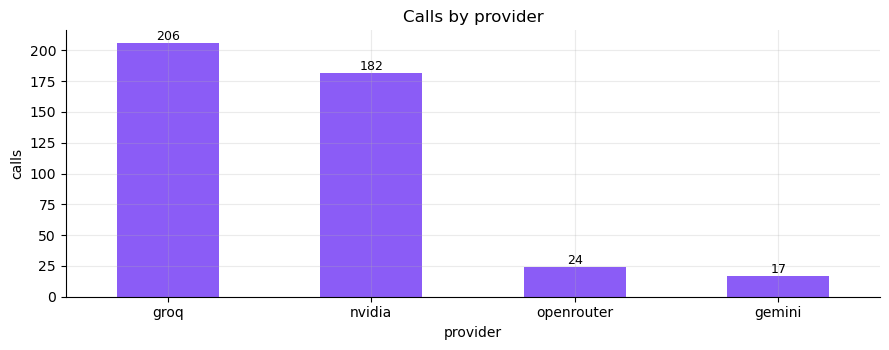

calls
provider   model                                   
groq       openai/gpt-oss-20b                   206
nvidia     nvidia/nemotron-3-ultra-550b-a55b    182
gemini     gemini-3.6-flash                      17
openrouter google/gemma-4-26b-a4b-it:free        12
           google/gemma-4-31b-it:free            12

In [2]:
mix = df.provider.value_counts()
ax = mix.plot.bar(color="#8B5CF6", title="Calls by provider")
ax.set_ylabel("calls")
for i, v in enumerate(mix.values):
    ax.text(i, v, f"{v}", ha="center", va="bottom", fontsize=9)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

models = (df.groupby(["provider", "model"]).size()
          .sort_values(ascending=False).rename("calls").to_frame())
models

**Takeaway:** Groq (`openai/gpt-oss-20b`) and Nvidia (`nemotron-3-ultra-550b`)
carried 388 of 429 calls. Gemini, the intended primary, served only 17 — it hits
its free daily cap the fastest.

## 2. Failure causes (why the chain fell through)

Semantics: the recorder stamps `fallback_reason` on the **winning** call when an
earlier provider in the chain failed. So every row with a `fallback_reason` is a
call where at least one provider was burned before this one succeeded.

,calls,share %
call_outcome,,
quota / 429,226,52.7
clean first-provider win,164,38.2
provider 400 / validation,38,8.9
transport,1,0.2


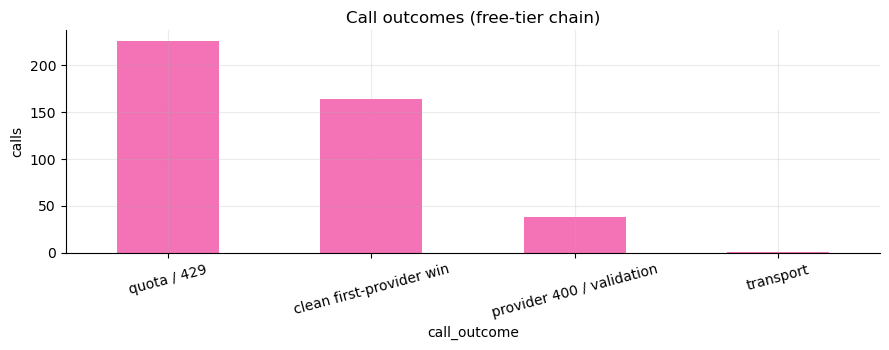

In [3]:
import re

def classify(reason: str) -> str:
    if reason is None or (isinstance(reason, float) and pd.isna(reason)):
        return "clean first-provider win"
    r = str(reason)
    if "429" in r or "RESOURCE_EXHAUSTED" in r or "rate-limited" in r:
        return "quota / 429"
    if "400" in r or "Failed to validate" in r or "Failed to generate" in r:
        return "provider 400 / validation"
    if "RetryError" in r:
        return "transport"
    return "other"

df["call_outcome"] = df.fallback_reason.map(classify)
counts = df.call_outcome.value_counts()
share = (counts / len(df) * 100).round(1)
summary = pd.DataFrame({"calls": counts, "share %": share})
display(summary)

ax = counts.plot.bar(color="#F472B6", title="Call outcomes (free-tier chain)")
ax.set_ylabel("calls")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [4]:
# Failure causes among the fallthroughs, and which provider finally won them
ft = df[df.fallback_reason.notna()]
causes = ft.fallback_reason.map(classify).value_counts()
print("Fallthrough causes:")
display(causes.to_frame("calls"))
print("Provider that finally won after a fallthrough:")
display(ft.provider.value_counts().to_frame("calls"))

Fallthrough causes:


,calls
fallback_reason,
quota / 429,226
provider 400 / validation,38
transport,1


Provider that finally won after a fallthrough:


,calls
provider,
nvidia,152
groq,93
openrouter,20


**Takeaway:** 265 of 429 calls (62%) only succeeded after burning an earlier
provider — and **85% of those burn-outs were quota (429s)**. This is the
statistical fingerprint of free-tier operation: the chain design (Gemini →
OpenRouter → Groq → Nvidia) is what keeps the pipeline alive at $0.

## 3. Latency by provider

,calls,median_ms,mean_ms,p90_ms,max_ms
provider,,,,,
groq,206.0,8161.0,10006.0,25120.0,71074.0
gemini,17.0,9475.0,11208.0,24467.0,27591.0
openrouter,24.0,33318.0,31009.0,51366.0,63177.0
nvidia,182.0,76126.0,84573.0,189203.0,336172.0


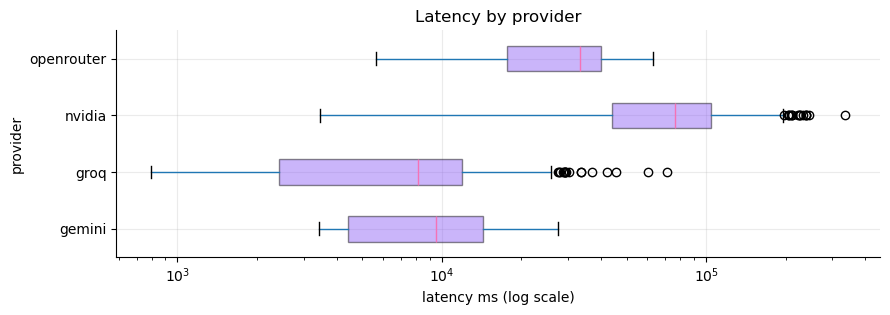

In [5]:
lat = (df.groupby("provider").latency_ms
       .agg(calls="count", median_ms="median", mean_ms="mean", p90_ms=lambda s: s.quantile(0.9), max_ms="max")
       .sort_values("median_ms") / 1)  # ms
lat[["median_ms", "mean_ms", "p90_ms", "max_ms"]] = lat[["median_ms", "mean_ms", "p90_ms", "max_ms"]].round(0)
display(lat)

ax = df.boxplot(column="latency_ms", by="provider", vert=False, figsize=(9, 3.4),
                patch_artist=True,
                boxprops=dict(facecolor="#8B5CF6", alpha=0.45),
                medianprops=dict(color="#F472B6"))
ax.set_xscale("log")
ax.set_xlabel("latency ms (log scale)")
ax.set_title("Latency by provider")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Takeaway:** Nvidia's Nemotron is a reasoning model — median **76 s per call**
(vs ~8 s for Groq), max **336 s**. That is why builds that land on Nvidia take
4+ minutes and occasionally time out (see `docs/RESULTS.md`, error register);
Groq is the latency workhorse, Nvidia is the reliability backstop.

## 4. Truncation — who cuts output off

In [6]:
fr = df.finish_reason.fillna("(missing)").value_counts()
display(fr.to_frame("calls"))

tr = df[df.finish_reason == "length"]
rate = (tr.groupby("provider").size() / df.groupby("provider").size() * 100).dropna().round(1)
print("Truncated share per provider (%):")
display(rate.to_frame("truncated %"))
if len(tr):
    print(f"{len(tr)} truncated calls, all on: {', '.join(sorted(tr.provider.unique()))}")

,calls
finish_reason,
stop,376
length,36
STOP,17


Truncated share per provider (%):


,truncated %
provider,
groq,17.5


36 truncated calls, all on: groq


**Takeaway:** 36 calls hit `finish_reason: length` — **17.5% of all Groq calls**,
all on `gpt-oss-20b`. Truncated JSON is the failure mode the parse ladder
(detect truncation → capped repair call) and `max_output_tokens` caps exist for.
No other provider truncated in this window.

## 5. Parse-outcome attribution — a gap this analysis found

The `llm_calls` schema has `parse_outcome` (`ok | repaired | llm_repaired | failed`)
and `repair_used` columns — but in this historical export they are **NULL on every
row**. Root cause: the recorder inserts the row the moment the provider returns,
*before* JSON parsing happens, and nothing wrote the outcome back afterwards.
Parse outcomes existed only at stage level (`AgentResult`), not per call.

That makes "parse success by provider" unanswerable from this table — so it was
fixed (session 33): the recorder returns its row id, the agent stamps the parse
outcome with a narrow follow-up UPDATE (migration 010 grants, column-scoped),
and every future call carries its own outcome.

In [7]:
have = df.parse_outcome.notna().sum()
print(f"rows with parse_outcome attributed: {have} / {len(df)}")
if have:
    per = (df.dropna(subset=["parse_outcome"])
             .groupby(["provider", "parse_outcome"]).size().unstack(fill_value=0))
    display(per)
    ok = df.parse_outcome.isin(["ok", "repaired", "llm_repaired"])
    print(f"overall parse success: {ok.sum()}/{df.parse_outcome.notna().sum()}")
else:
    print("No attributed rows yet — this is the historical export.")
    print("Run live builds after applying migration 010, then re-export.")

rows with parse_outcome attributed: 0 / 429
No attributed rows yet — this is the historical export.
Run live builds after applying migration 010, then re-export.


## Findings (2026-10-12 → 2026-10-16 window)

- **Provider mix:** Groq 206, Nvidia 182, OpenRouter 24, Gemini 17. The
  "primary" provider (Gemini) served 4% of calls — free daily caps make the
  fallback chain the actual production path.
- **62% of calls (265/429) succeeded only after a provider fallthrough.**
  85% of the causes are quota/429 — the dominant failure class is *not* model
  quality, it's free-tier capacity. A paid key removes it overnight.
- **Provider-side 400s (38)** are the second class: upstream capacity/validation
  errors on free models, handled by the same chain.
- **Latency:** Groq ~8 s median vs Nvidia ~76 s median (reasoning model, up to
  336 s). Median build wall time tracks which provider won (§4.4 min in core20).
- **Truncation:** 17.5% of Groq calls end at `finish_reason: length` — JSON
  truncation is a routine occurrence, not an edge case; the parse ladder's
  truncation detection + capped repair call is load-bearing.
- **Schema gap found and fixed:** parse outcomes were tracked per *stage* but
  never per *call*; session 33 wired row-id attribution end-to-end (+ migration
  010 for the narrow update policy). Historical rows stay NULL by design.

**Next:** with paid quota (or after more free runs on the fixed recorder),
re-run this notebook and the §5 cell becomes a per-provider parse-success table —
the honest reliability comparison the project's README claims.

---
*Regenerate:* build some wishes (Studio or `scripts/core20.py --live`), then
`python scripts/export_llm_calls.py` and re-run all cells.